# Adam Optimizer: why the "default" way to train neural networks works

**The question:** every neural network is trained by an **optimiser**, a rule that nudges millions of numbers a little at a time to make the model's error smaller. The most popular rule today is **Adam**. What does it actually do, does it really get to the answer faster than the older rules, and when does that advantage vanish?

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note. We build Adam by hand, *prove* it matches PyTorch's, race it fairly against three rivals, and finish on a real neural network.

1. The analogy
2. Setup
3. The maths of Adam, in plain words
4. Adam from scratch (and a unit test)
5. Hypotheses and experimental design
6. A fair race on a lopsided problem
7. The curved valley (a picture)
8. How fussy is each optimiser about its learning rate?
9. A real network: MNIST digits
10. Takeaways
11. Limitations

**Run it:** `uv run jupyter lab DL/adam-optimizer/adam_optimizer.ipynb`, or *Run All* in any Jupyter. MNIST (about 12 MB) downloads itself on the first run. It uses a GPU if one is present, and takes about 10 minutes either way.

## 1. 💡 The simple analogy

Imagine **hikers walking down a foggy valley** to reach the lowest point. They can't see the valley; they can only feel the slope under their feet.

- **Plain SGD (stochastic gradient descent)** is the cautious hiker: *look at the slope right here, take a step downhill.* Simple, but in a long, narrow valley they zig-zag across the steep walls while barely moving along the gentle floor.
- **SGD with momentum** is a **rolling ball**: it builds up speed in the direction it has been heading, so the zig-zags cancel out and it glides along the valley floor.
- **RMSprop and Adam** add a clever trick: they wear **different shoes for different directions**. Where the ground has been bumpy and steep, they take small careful steps; where it has been flat and quiet, they take big confident ones. Adam combines the **rolling ball** (momentum) with the **adaptive shoes** (RMSprop).

The question for the rest of the notebook is simple: *does that extra cleverness actually get hikers to the bottom faster, and does it still help once we are on a real, big network?*

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the random seed and the step budget keeps the notebook reproducible and avoids "magic numbers". With the seeds fixed, every experiment comes out the same each time you run it.

In [1]:
import contextlib
import io
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from torch import nn
from torchvision import datasets

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
SEED = 42
N_TUNE_SEEDS = 5
N_EVAL_SEEDS = 30
STEP_BUDGET = 6_000
CONVERGED = 0.01  # a run "converges" once it closes 99% of the gap to the optimum...
STAY_POINTS = 20  # ...and stays there: the average over 20 recordings (200 steps) is below it
BATCH_SIZE = 64
N_BOOTSTRAP = 5_000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"
OPT_COLORS = {"SGD": GREY, "SGD + momentum": NAVY, "RMSprop": PURPLE, "Adam": ORANGE}

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if p < 1e-300 else f"{p:.1e}"

## 3. The maths of Adam, in plain words

Training means repeatedly finding the **gradient** $g_t$ (the slope of the error at the current numbers $\theta_t$) and stepping against it. Each optimiser turns the gradient into a step differently:

| Optimiser | Rule (per step $t$) | In plain words |
|---|---|---|
| **SGD** | $\theta_t = \theta_{t-1} - \alpha\, g_t$ | Step straight downhill by a fixed amount |
| **SGD + momentum** | $v_t = 0.9\, v_{t-1} + g_t$, then $\theta_t = \theta_{t-1} - \alpha\, v_t$ | Keep rolling in the direction you've been going |
| **RMSprop** | $s_t = 0.99\, s_{t-1} + 0.01\, g_t^2$, then $\theta_t = \theta_{t-1} - \alpha\, g_t / (\sqrt{s_t} + \epsilon)$ | Shrink steps where the slope has been large; enlarge them where it has been small |
| **Adam** | $m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t$, $\; v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2$, $\; \hat m_t = m_t/(1-\beta_1^t)$, $\; \hat v_t = v_t/(1-\beta_2^t)$, $\; \theta_t = \theta_{t-1} - \alpha\, \hat m_t / (\sqrt{\hat v_t} + \epsilon)$ | Momentum ($m_t$) **and** adaptive step sizes ($v_t$) together |

Adam's four numbers are $\alpha$ (the learning rate, usually 0.001), $\beta_1 = 0.9$ (how long the rolling ball remembers), $\beta_2 = 0.999$ (how long the "bumpiness" memory lasts) and a tiny $\epsilon = 10^{-8}$ (so we never divide by zero). The two *hat* lines are the **bias correction**: $m_t$ and $v_t$ start at zero, so for the first few steps they are too small, and dividing by $1-\beta^t$ fixes that.

The key property: the update $\hat m_t / \sqrt{\hat v_t}$ is a *ratio*, so it doesn't care whether a direction's gradients are in the thousands or the thousandths: **every parameter moves at about the same pace, about $\alpha$ per step**. That is the "different shoes" trick, and it is why Adam copes with lopsided problems.

## 4. Adam from scratch (and a unit test)

*What:* we write Adam ourselves in a few lines of NumPy, following the table above line by line. *Why:* writing it by hand is the best way to see there is no magic in it. A few lines of arithmetic, nothing more.

In [2]:
class AdamFromScratch:
    """Adam (Kingma and Ba, 2015) written out step by step with NumPy.

    Args:
        params: Starting parameter vector (a float array, updated in place).
        lr: Learning rate (alpha).
        beta1: Decay rate of the running average of gradients (the "velocity").
        beta2: Decay rate of the running average of squared gradients (the "bumpiness").
        eps: Tiny number that prevents division by zero.
    """

    def __init__(
        self,
        params: np.ndarray,
        lr: float = 1e-3,
        beta1: float = 0.9,
        beta2: float = 0.999,
        eps: float = 1e-8,
    ) -> None:
        self.params, self.lr, self.beta1, self.beta2, self.eps = params, lr, beta1, beta2, eps
        self.m = np.zeros_like(params)
        self.v = np.zeros_like(params)
        self.t = 0

    def step(self, grad: np.ndarray) -> np.ndarray:
        """Takes one Adam step.

        Args:
            grad: Gradient of the loss at the current parameters.

        Returns:
            The updated parameter vector.
        """
        self.t += 1
        self.m = self.beta1 * self.m + (1 - self.beta1) * grad
        self.v = self.beta2 * self.v + (1 - self.beta2) * grad**2
        m_hat = self.m / (1 - self.beta1**self.t)  # undo the start-up bias towards zero
        v_hat = self.v / (1 - self.beta2**self.t)
        self.params -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)
        return self.params

**A unit test, because "I think it's right" isn't evidence.** *What:* we run our Adam and `torch.optim.Adam` side by side on the same bowl-shaped problem for 300 steps and compare the numbers after every step. **H₁ (the check):** the largest difference is essentially zero (below one billionth). If our implementation had a bug (a missing bias correction, a swapped β) the two paths would drift apart and the `assert` would stop the notebook.

In [3]:
def adam_matches_pytorch(steps: int = 300) -> float:
    """Runs both Adams on the same quadratic and returns the largest parameter difference.

    Args:
        steps: Number of optimisation steps.

    Returns:
        Maximum absolute difference between the two parameter trajectories.
    """
    rng = np.random.default_rng(SEED)
    matrix = rng.normal(size=(6, 6))
    curvature = matrix.T @ matrix + np.eye(6)  # a bowl: loss = 0.5 * theta' A theta
    start = rng.normal(size=6)

    mine = AdamFromScratch(start.copy(), lr=0.05)
    theirs = torch.tensor(start.copy(), dtype=torch.float64, requires_grad=True)
    reference = torch.optim.Adam([theirs], lr=0.05)
    largest = 0.0
    for _ in range(steps):
        mine.step(curvature @ mine.params)
        reference.zero_grad()
        (0.5 * theirs @ torch.tensor(curvature) @ theirs).backward()
        reference.step()
        largest = max(largest, float(np.abs(mine.params - theirs.detach().numpy()).max()))
    return largest


difference = adam_matches_pytorch()
print(f"Largest difference between my Adam and torch.optim.Adam over 300 steps: {difference:.2e}")
assert difference < 1e-9, "The from-scratch Adam does not match PyTorch"

Largest difference between my Adam and torch.optim.Adam over 300 steps: 1.94e-16


## 5. 🔬 Hypotheses and experimental design

Here are the questions, each with its null (H₀, "nothing special") and alternative (Hₐ), written **before** looking at any result:

| # | Question | H₀ | Hₐ | Method |
|---|---|---|---|---|
| H1 | Does our Adam equal PyTorch's? | They differ | They agree to rounding | Step-by-step comparison over 300 steps (a deterministic check, not a statistical test) |
| H2 | On a lopsided problem, does Adam need fewer steps than the others? | Same number of steps | Adam needs fewer | 30 random problems per optimiser; Mann-Whitney U, Cliff's δ, bootstrap CI for the ratio of medians |
| H3 | Is Adam less fussy about its learning rate? | Same share of working learning rates | Adam works over a wider range | 13 learning rates × 10 problems; Wilson CIs |
| H4 | On a real network (MNIST), does Adam reach higher accuracy early? | No difference | Adam is more accurate after 1 epoch | 10 paired seeds; Wilcoxon signed-rank, bootstrap CI |
| H5 | Does the gap survive five epochs, once the rivals are tuned? | No difference | A gap remains | Same paired comparison after epoch 5 |

**The test bed (H2, H3): an ill-conditioned linear regression.** We fit a straight line through data whose ten features live on very different scales (from 1 to 100). Some directions are therefore **100 times steeper** than others, and the loss surface is a long thin valley, the exact kind of terrain where optimisers differ most. We train with **mini-batches of 64**, so every step is a noisy estimate of the true slope, like real deep learning. A run **converges** when it has closed **99% of the gap** between the starting loss and the best possible loss, and we count the **steps** it took. Runs that never get there within the budget of 6,000 steps are **censored**: we record the budget as their value and report the share that failed.

**Why Mann-Whitney U and Cliff's δ?** Step counts are skewed and some are censored, so a rank-based test is safer than comparing averages. Mann-Whitney lines all runs up from fastest to slowest and asks whether one optimiser's runs tend to sit earlier in the line. **Cliff's δ** is *P(Adam is slower) − P(Adam is faster)* (negative means Adam is faster), from −1 to +1 (|δ| about 0.15 small, 0.33 medium, 0.47 large). **Why a bootstrap CI for the ratio of medians?** It gives a plain-English answer ("Adam needs about a third of the steps") with an honest range, by re-drawing the 30 runs with replacement 5,000 times.

In [4]:
class Optimizer:
    """A small family of first-order optimisers sharing one interface.

    Args:
        kind: ``"SGD"``, ``"SGD + momentum"``, ``"RMSprop"`` or ``"Adam"``.
        params: Starting parameter vector (copied).
        lr: Learning rate.
    """

    def __init__(self, kind: str, params: np.ndarray, lr: float) -> None:
        self.kind, self.params, self.lr = kind, params.copy(), lr
        self.buffer = np.zeros_like(params)
        self.second = np.zeros_like(params)
        self.t = 0

    def step(self, grad: np.ndarray) -> None:
        """Takes one step along ``grad`` according to the optimiser's rule.

        Args:
            grad: Gradient of the loss at the current parameters.
        """
        self.t += 1
        if self.kind == "SGD":
            self.params -= self.lr * grad
        elif self.kind == "SGD + momentum":
            self.buffer = 0.9 * self.buffer + grad
            self.params -= self.lr * self.buffer
        elif self.kind == "RMSprop":
            self.second = 0.99 * self.second + 0.01 * grad**2
            self.params -= self.lr * grad / (np.sqrt(self.second) + 1e-8)
        else:  # Adam
            self.buffer = 0.9 * self.buffer + 0.1 * grad
            self.second = 0.999 * self.second + 0.001 * grad**2
            m_hat = self.buffer / (1 - 0.9**self.t)
            v_hat = self.second / (1 - 0.999**self.t)
            self.params -= self.lr * m_hat / (np.sqrt(v_hat) + 1e-8)


def make_problem(seed: int, n: int = 500, d: int = 10) -> dict:
    """Builds an ill-conditioned linear regression problem.

    The features live on very different scales (1 to 100), so some directions are
    100 times steeper than others, and the loss surface is a long thin valley.

    Args:
        seed: Random seed for the data.
        n: Number of examples.
        d: Number of features.

    Returns:
        Dictionary with the data, the optimal loss and the starting loss.
    """
    rng = np.random.default_rng(seed)
    scales = np.logspace(0, 2, d)
    x = rng.normal(size=(n, d)) * scales
    weights = rng.normal(size=d) / scales
    y = x @ weights + 0.5 * rng.normal(size=n)
    best = np.linalg.lstsq(x, y, rcond=None)[0]
    loss = lambda w: 0.5 * np.mean((x @ w - y) ** 2)  # noqa: E731
    return {
        "x": x,
        "y": y,
        "loss": loss,
        "optimum": loss(best),
        "start": loss(np.zeros(d)),
        "d": d,
        "n": n,
    }


def run_regression(kind: str, lr: float, problem: dict, seed: int) -> tuple[np.ndarray, np.ndarray]:
    """Trains one optimiser on the regression problem with mini-batches.

    Args:
        kind: Which optimiser to use.
        lr: Learning rate.
        problem: Output of :func:`make_problem`.
        seed: Seed for the mini-batch order.

    Returns:
        Step numbers (every 10 steps) and the matching *relative gap*: how much of the
        distance between the starting loss and the best possible loss is still left.
    """
    rng = np.random.default_rng(seed)
    x, y = problem["x"], problem["y"]
    optimiser = Optimizer(kind, np.zeros(problem["d"]), lr)
    steps = np.arange(0, STEP_BUDGET + 1, 10)
    gaps = np.full(len(steps), np.inf)  # a run that blows up keeps an infinite gap
    with np.errstate(all="ignore"):
        for step in range(STEP_BUDGET + 1):
            if step % 10 == 0:
                gap = (problem["loss"](optimiser.params) - problem["optimum"]) / (
                    problem["start"] - problem["optimum"]
                )
                if not np.isfinite(gap) or gap > 1e12:
                    break  # diverged: stop and leave the rest of the curve at infinity
                gaps[step // 10] = gap
            rows = rng.integers(0, problem["n"], BATCH_SIZE)
            grad = x[rows].T @ (x[rows] @ optimiser.params - y[rows]) / BATCH_SIZE
            optimiser.step(grad)
    return steps, gaps


def steps_to_converge(steps: np.ndarray, gaps: np.ndarray) -> int:
    """First step at which the gap has stayed below the threshold, on average, for 200 steps.

    Requiring the *average over a window* (not a single lucky dip) stops a jumpy optimiser
    from being credited for touching the finish line and then bouncing away.

    Args:
        steps: Step numbers (one per recording, every 10 steps).
        gaps: Relative gap at each recording.

    Returns:
        The step number, or the budget if the run never converged (a censored value).
    """
    window = np.convolve(gaps, np.ones(STAY_POINTS) / STAY_POINTS, mode="valid")
    reached = np.where(window <= CONVERGED)[0]
    return int(steps[reached[0] + STAY_POINTS - 1]) if len(reached) else STEP_BUDGET

### A fair race starts with fair tuning

*What:* each optimiser has a **learning rate** that matters enormously, and a rival run at a bad learning rate would make Adam look better than it deserves. So before racing, we give every optimiser its **best** learning rate, found on **separate "tuning" problems** (5 problems, seeds 0 to 4) by trying 13 values from $10^{-6}$ to 1 and keeping the one with the lowest median steps to converge. The race then uses **different problems** (30 fresh ones), so a learning rate cannot be "overfitted" to the problems it is judged on.

In [5]:
LR_GRID = np.logspace(-6, 0, 13)
OPTIMIZERS = list(OPT_COLORS)
tune_problems = [make_problem(seed) for seed in range(N_TUNE_SEEDS)]

RELIABLE = 0.8  # a learning rate is only eligible if at least 80% of tuning runs converge


def tune(kind: str) -> tuple[float, dict[str, float]]:
    """Picks the fastest learning rate among those that converge reliably.

    Args:
        kind: Optimiser name.

    Returns:
        The chosen learning rate and a summary of how it did on the tuning problems.
    """
    table = {}
    for lr in LR_GRID:
        runs = [run_regression(kind, lr, p, seed) for seed, p in enumerate(tune_problems)]
        steps = np.array([steps_to_converge(s, g) for s, g in runs])
        table[lr] = {
            "steps": float(np.median(steps)),
            "success": float(np.mean(steps < STEP_BUDGET)),
            "gap": float(np.median([g[-STAY_POINTS:].mean() for _, g in runs])),
        }
    frame = pd.DataFrame(table).T
    eligible = frame[frame["success"] >= RELIABLE]
    # Fastest among the reliable ones; if none is reliable, the smallest final gap.
    choice = eligible["steps"].idxmin() if len(eligible) else frame["gap"].idxmin()
    return float(choice), frame.loc[choice].to_dict()


tuned = {kind: tune(kind) for kind in OPTIMIZERS}
best_lr = pd.Series({kind: lr for kind, (lr, _) in tuned.items()})
print(
    "Learning rate chosen for each optimiser on the tuning problems "
    f"(fastest among those converging in at least {RELIABLE:.0%} of runs):"
)
print(
    pd.DataFrame({kind: info for kind, (_, info) in tuned.items()})
    .T.assign(**{"best lr": best_lr})[["best lr", "steps", "success", "gap"]]
    .to_string(float_format=lambda v: f"{v:.3g}")
)

Learning rate chosen for each optimiser on the tuning problems (fastest among those converging in at least 80% of runs):
                best lr    steps  success     gap
SGD              0.0001    6e+03      0.4  0.0141
SGD + momentum   0.0001 1.17e+03        1 0.00616
RMSprop           0.001      450        1 0.00132
Adam            0.00316      280        1 0.00311


## 6. A fair race on a lopsided problem

*What:* 30 fresh problems × 4 optimisers, each at its tuned learning rate. *How to read the results:* the left chart shows how fast each optimiser closes the loss gap (lower is better, log scale); the right chart shows the steps each run needed (lower is better; the dotted line is the budget, so dots on it never converged).

In [6]:
eval_problems = [make_problem(1000 + seed) for seed in range(N_EVAL_SEEDS)]
curves, steps_needed = {}, {}
for kind in OPTIMIZERS:
    runs = [
        run_regression(kind, best_lr[kind], p, 1000 + seed) for seed, p in enumerate(eval_problems)
    ]
    curves[kind] = np.array([gaps for _, gaps in runs])
    steps_needed[kind] = np.array([steps_to_converge(s, g) for s, g in runs])
grid_steps = runs[0][0]

summary = pd.DataFrame(
    {
        kind: {
            "median steps": np.median(v),
            "share converged": np.mean(v < STEP_BUDGET),
            "median final gap": np.median(curves[kind][:, -STAY_POINTS:].mean(axis=1)),
        }
        for kind, v in steps_needed.items()
    }
).T
summary.style.format(
    {"median steps": "{:.0f}", "share converged": "{:.0%}", "median final gap": "{:.3f}"}
)

,median steps,share converged,median final gap
SGD,6000,33%,0.019
SGD + momentum,1420,97%,0.005
RMSprop,805,100%,0.001
Adam,455,100%,0.002


In [7]:
def cliffs_delta(a: np.ndarray, b: np.ndarray) -> float:
    """Cliff's delta: P(a > b) - P(a < b), computed from ranks.

    Args:
        a: Values in group A.
        b: Values in group B.

    Returns:
        Effect size between -1 and +1.
    """
    ranks = stats.rankdata(np.concatenate([a, b]))
    u = ranks[: len(a)].sum() - len(a) * (len(a) + 1) / 2
    return float(2 * u / (len(a) * len(b)) - 1)


def median_ratio_ci(a: np.ndarray, b: np.ndarray, rng: np.random.Generator) -> tuple:
    """Bootstrap 95% CI for median(a) / median(b).

    Args:
        a: Values in group A.
        b: Values in group B.
        rng: Random generator.

    Returns:
        Observed ratio, CI lower bound, CI upper bound.
    """
    boot_a = np.median(rng.choice(a, (N_BOOTSTRAP, len(a))), axis=1)
    boot_b = np.median(rng.choice(b, (N_BOOTSTRAP, len(b))), axis=1)
    lo, hi = np.percentile(boot_a / boot_b, [2.5, 97.5])
    return float(np.median(a) / np.median(b)), float(lo), float(hi)


rng = np.random.default_rng(SEED)
rows = {}
for rival in ("SGD", "SGD + momentum", "RMSprop"):
    test = stats.mannwhitneyu(steps_needed["Adam"], steps_needed[rival])
    ratio, lo, hi = median_ratio_ci(steps_needed["Adam"], steps_needed[rival], rng)
    rows[f"Adam vs {rival}"] = {
        "Adam median steps": np.median(steps_needed["Adam"]),
        f"{rival} median steps": np.median(steps_needed[rival]),
        "ratio": ratio,
        "ci_low": lo,
        "ci_high": hi,
        "cliffs_delta": cliffs_delta(steps_needed["Adam"], steps_needed[rival]),
        "p": test.pvalue,
    }
race = pd.DataFrame(rows).T
race.iloc[:, [0, 2, 3, 4, 5, 6]].style.format(
    {
        "Adam median steps": "{:.0f}",
        "ratio": "{:.2f}",
        "ci_low": "{:.2f}",
        "ci_high": "{:.2f}",
        "cliffs_delta": "{:+.2f}",
        "p": fmt_p,
    }
)

,Adam median steps,ratio,ci_low,ci_high,cliffs_delta,p
Adam vs SGD,455,0.08,0.05,0.10,-1.00,1.3e-11
Adam vs SGD + momentum,455,0.32,0.22,0.47,-0.89,2.8e-09
Adam vs RMSprop,455,0.57,0.35,0.89,-0.54,3.7e-04


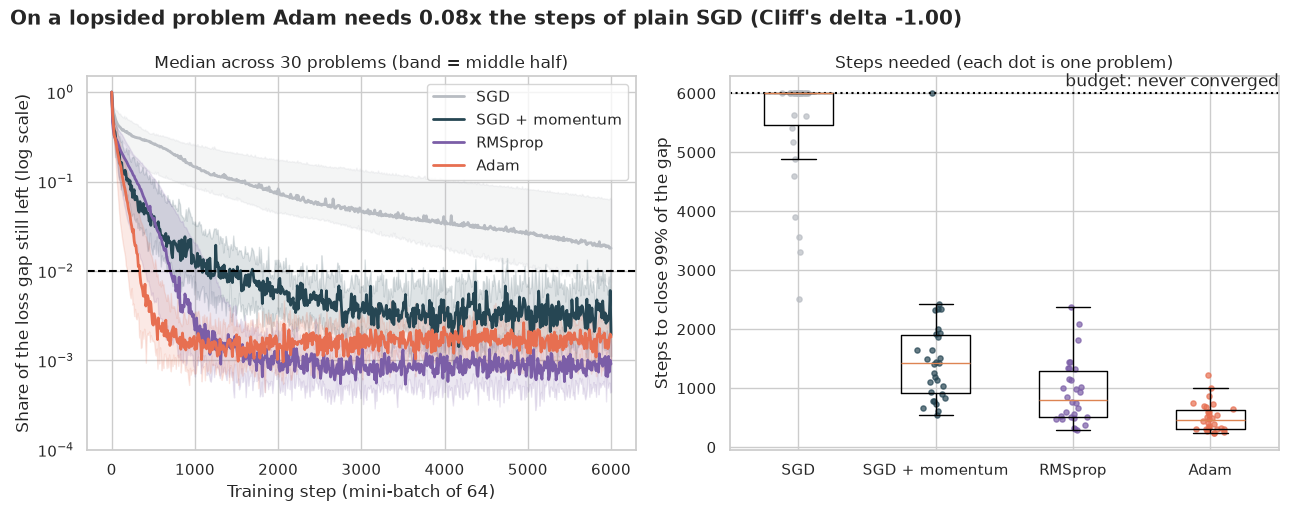

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for kind in OPTIMIZERS:
    median = np.median(curves[kind], axis=0)
    low, high = np.percentile(curves[kind], [25, 75], axis=0)
    axes[0].plot(grid_steps, median, color=OPT_COLORS[kind], lw=2, label=kind)
    axes[0].fill_between(grid_steps, low, high, color=OPT_COLORS[kind], alpha=0.15)
axes[0].axhline(CONVERGED, color="black", ls="--")
axes[0].set_yscale("log")
axes[0].set_ylim(1e-4, 1.5)
axes[0].set_xlabel("Training step (mini-batch of 64)")
axes[0].set_ylabel("Share of the loss gap still left (log scale)")
axes[0].legend()
axes[0].set_title("Median across 30 problems (band = middle half)")

positions = np.arange(len(OPTIMIZERS))
data = [steps_needed[k] for k in OPTIMIZERS]
axes[1].boxplot(data, positions=positions, widths=0.5, showfliers=False)
for pos, kind in zip(positions, OPTIMIZERS, strict=True):
    jitter = np.random.default_rng(pos).normal(0, 0.05, N_EVAL_SEEDS)
    axes[1].scatter(pos + jitter, steps_needed[kind], s=14, color=OPT_COLORS[kind], alpha=0.7)
axes[1].axhline(STEP_BUDGET, color="black", ls=":")
axes[1].text(len(OPTIMIZERS) - 0.5, STEP_BUDGET * 1.02, "budget: never converged", ha="right")
axes[1].set_xticks(positions, OPTIMIZERS)
axes[1].set_ylabel("Steps to close 99% of the gap")
axes[1].set_title("Steps needed (each dot is one problem)")
adam_vs_sgd = race.loc["Adam vs SGD"]
fig.suptitle(
    f"On a lopsided problem Adam needs {adam_vs_sgd['ratio']:.2f}x the steps of plain SGD "
    f"(Cliff's delta {adam_vs_sgd['cliffs_delta']:+.2f})",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_race.png", dpi=150)
plt.show()

**How to read this.** (The table above gives each optimiser's median steps, the share of its 30 runs that converged, and the average gap left at the end.)

- **Plain SGD struggles.** Even at its best stable learning rate it converges on only **33%** of the 30 problems within 6,000 steps (the grey box sits on the budget line). It zig-zags across the steep walls and creeps along the gentle floor.
- **Momentum helps a lot** (97% converge, median **1,420** steps), **RMSprop** converges on every problem in a median **805** steps, and **Adam** converges on every problem in a median **455** steps.
- **The tests (H₂): we reject H₀ against all three rivals.** Adam needs about **0.08 times the steps of SGD** (95% CI 0.05 to 0.10; Cliff's δ = −1.00, p ≈ 1e-11), about **0.32 times those of SGD + momentum** (CI 0.22 to 0.47; δ = −0.89, p ≈ 3e-9) and about **0.57 times those of RMSprop** (CI 0.35 to 0.89; δ = −0.54, p ≈ 4e-4). Because the SGD runs that never converged are recorded at the budget, the SGD ratio is really a *bound*: SGD would need *more* than 6,000 steps, so the true advantage is bigger still.
- **Left chart:** the orange Adam curve plunges almost immediately and stays low; the navy momentum curve gets there later; the grey SGD curve is still falling slowly when the budget ends.

> **A lesson from building this test.** An earlier version counted a run as converged the *first time* it touched the 99% line. RMSprop, run at an aggressive learning rate, touched it first, then bounced around a 10% gap and never settled, yet looked like the winner. We changed the rule: convergence now means the gap's **average over 200 steps** stays under the line, and the learning rates are tuned among those that converge **reliably** (at least 80% of the tuning runs). "How fast" must always be paired with "does it stay there".

## 7. The curved valley (a picture)

*What:* a two-dimensional picture of the same idea. The **Rosenbrock function** is a famous test terrain: a long, curved, banana-shaped valley whose floor slopes only very gently towards the goal at (1, 1), while its walls are extremely steep. We start the four optimisers at the same point and trace their paths for 3,000 steps. *How to read:* the grey lines are contour lines (closer together = steeper); a good optimiser follows the curved floor to the star.

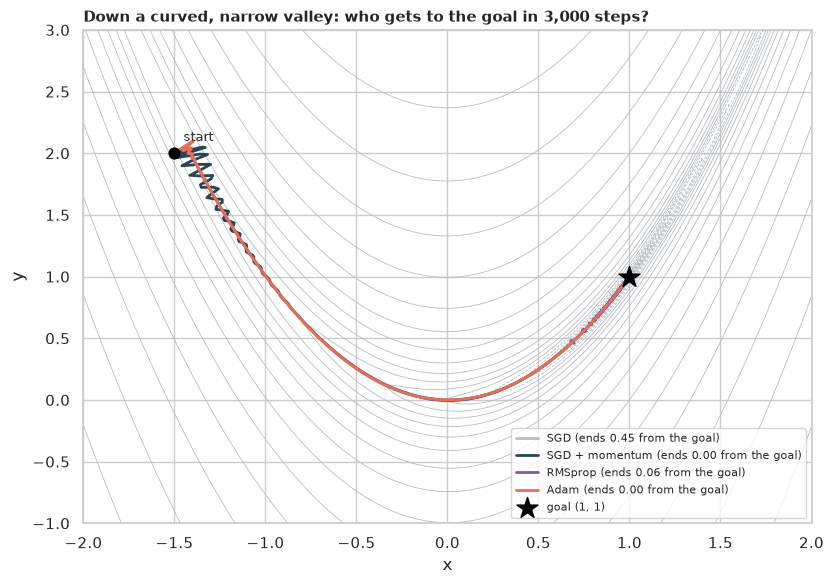

Learning rate chosen by grid search, and final distance from the goal:
{'SGD': ('1.0e-03', 0.451), 'SGD + momentum': ('1.0e-03', 0.0), 'RMSprop': ('3.2e-03', 0.055), 'Adam': ('3.2e-02', 0.0)}


In [9]:
def rosenbrock(point: np.ndarray) -> float:
    """The Rosenbrock "banana valley" function, minimised at (1, 1).

    Args:
        point: A 2-vector (x, y).

    Returns:
        The function value.
    """
    return float((1 - point[0]) ** 2 + 100 * (point[1] - point[0] ** 2) ** 2)


def rosenbrock_grad(point: np.ndarray) -> np.ndarray:
    """Gradient of the Rosenbrock function.

    Args:
        point: A 2-vector (x, y).

    Returns:
        The gradient.
    """
    x, y = point
    return np.array([-2 * (1 - x) - 400 * x * (y - x**2), 200 * (y - x**2)])


def ravine_run(kind: str, lr: float, steps: int = 3_000) -> np.ndarray:
    """Follows an optimiser's path down the Rosenbrock valley.

    Args:
        kind: Optimiser name.
        lr: Learning rate.
        steps: Number of steps.

    Returns:
        Array of shape (steps + 1, 2) holding the path.
    """
    optimiser = Optimizer(kind, np.array([-1.5, 2.0]), lr)
    path = [optimiser.params.copy()]
    for _ in range(steps):
        optimiser.step(np.clip(rosenbrock_grad(optimiser.params), -1e3, 1e3))
        path.append(optimiser.params.copy())
    return np.array(path)


ravine_grid = np.logspace(-5, -0.5, 10)
ravine_lr, paths = {}, {}
with np.errstate(all="ignore"):
    for kind in OPTIMIZERS:
        trials = {lr: ravine_run(kind, lr) for lr in ravine_grid}
        finish = {lr: np.linalg.norm(path[-1] - 1.0) for lr, path in trials.items()}
        finish = {lr: d if np.isfinite(d) else np.inf for lr, d in finish.items()}
        ravine_lr[kind] = min(finish, key=finish.get)
        paths[kind] = trials[ravine_lr[kind]]
distance = {kind: float(np.linalg.norm(path[-1] - 1.0)) for kind, path in paths.items()}

xs, ys = np.meshgrid(np.linspace(-2, 2, 300), np.linspace(-1, 3, 300))
zs = (1 - xs) ** 2 + 100 * (ys - xs**2) ** 2
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.contour(xs, ys, np.log10(zs + 1e-3), levels=25, colors=GREY, linewidths=0.6)
for kind, path in paths.items():
    ax.plot(
        path[:, 0],
        path[:, 1],
        color=OPT_COLORS[kind],
        lw=2,
        label=f"{kind} (ends {distance[kind]:.2f} from the goal)",
    )
ax.scatter([1], [1], marker="*", s=250, color="black", zorder=5, label="goal (1, 1)")
ax.scatter([-1.5], [2], marker="o", s=60, color="black", zorder=5)
ax.text(-1.45, 2.1, "start", fontsize=9)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend(fontsize=8, loc="lower right")
ax.set_title(
    "Down a curved, narrow valley: who gets to the goal in 3,000 steps?",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_ravine.png", dpi=150)
plt.show()
print("Learning rate chosen by grid search, and final distance from the goal:")
print({kind: (f"{ravine_lr[kind]:.1e}", round(d, 3)) for kind, d in distance.items()})

**How to read this.** Each optimiser got its own learning rate from a small grid search (the legend shows how far from the goal it ended after 3,000 steps). **Adam and SGD + momentum both reach the goal** (distance 0.00), **RMSprop** ends close (0.06) and **plain SGD** is still crawling along the valley floor (0.45 away). The dark momentum path shows the signature wiggle at the start (the rolling ball overshooting and settling) before gliding down the floor, while Adam's path is smooth from the first step because its per-direction step sizes stop it bouncing between the walls.

This picture comes from **one starting point**, so it is an illustration, not a statistical test: the 30-problem race above is the evidence.

## 8. How fussy is each optimiser about its learning rate?

*What:* in practice you rarely know the best learning rate in advance. So how forgiving is each optimiser if you pick it badly? We re-run the race at **all 13 learning rates**, on 10 fresh problems each, and count how many learning rates **work** (at least half the runs converge within the budget). A wider "working range" means less tuning. We give each count a **Wilson 95% confidence interval** (a well-behaved CI for a proportion) over the 13-point grid. *How to read the heat-map:* each cell is the median steps needed (dark = fast, pale = slow), and a grey **x** marks a learning rate where the optimiser fails.

In [10]:
N_SENSITIVITY_SEEDS = 10
sens_problems = [make_problem(2000 + seed) for seed in range(N_SENSITIVITY_SEEDS)]
median_steps = pd.DataFrame(index=LR_GRID, columns=OPTIMIZERS, dtype=float)
success = pd.DataFrame(index=LR_GRID, columns=OPTIMIZERS, dtype=float)
for kind in OPTIMIZERS:
    for lr in LR_GRID:
        runs = np.array(
            [
                steps_to_converge(*run_regression(kind, lr, p, 2000 + seed))
                for seed, p in enumerate(sens_problems)
            ]
        )
        median_steps.loc[lr, kind] = np.median(runs)
        success.loc[lr, kind] = np.mean(runs < STEP_BUDGET)

working = (success >= 0.5).sum()
width_decades = working * (np.log10(LR_GRID[1]) - np.log10(LR_GRID[0]))
robustness = pd.DataFrame(
    {
        "learning rates that work (of 13)": working,
        "range of working rates (decades)": width_decades,
    }
)
for kind in OPTIMIZERS:
    lo, hi = proportion_confint(int(working[kind]), len(LR_GRID), method="wilson")
    robustness.loc[kind, "share of the grid (95% CI)"] = (
        f"{working[kind] / len(LR_GRID):.0%} ({lo:.0%} to {hi:.0%})"
    )
robustness.style.format({"range of working rates (decades)": "{:.1f}"})

,learning rates that work (of 13),range of working rates (decades),share of the grid (95% CI)
SGD,1,0.5,8% (1% to 33%)
SGD + momentum,3,1.5,23% (8% to 50%)
RMSprop,3,1.5,23% (8% to 50%)
Adam,6,3.0,46% (23% to 71%)


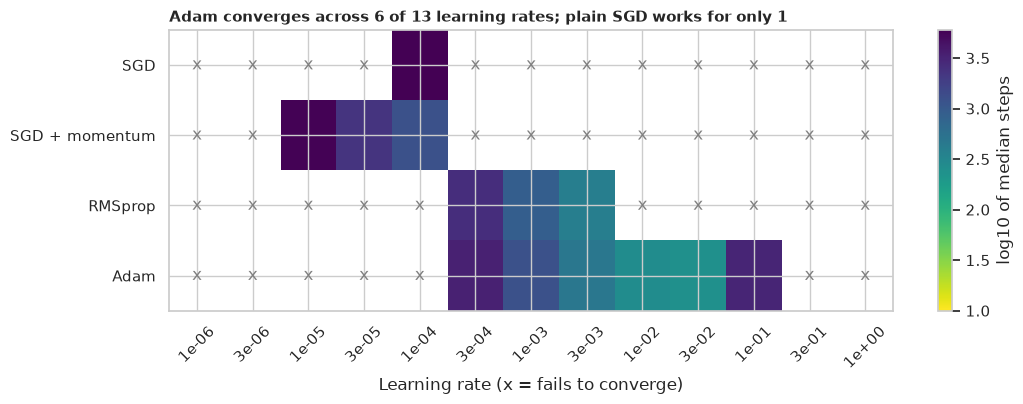

In [11]:
fig, ax = plt.subplots(figsize=(11, 4.2))
display_steps = median_steps.where(success >= 0.5)
image = ax.imshow(
    np.log10(display_steps.T.astype(float)),
    aspect="auto",
    cmap="viridis_r",
    vmin=1,
    vmax=np.log10(STEP_BUDGET),
)
ax.set_xticks(range(len(LR_GRID)), [f"{lr:.0e}" for lr in LR_GRID], rotation=45)
ax.set_yticks(range(len(OPTIMIZERS)), OPTIMIZERS)
for row, kind in enumerate(OPTIMIZERS):
    for col, lr in enumerate(LR_GRID):
        if success.loc[lr, kind] < 0.5:
            ax.text(col, row, "x", ha="center", va="center", color="grey")
ax.set_xlabel("Learning rate (x = fails to converge)")
colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("log10 of median steps")
ax.set_title(
    f"Adam converges across {working['Adam']} of 13 learning rates; plain SGD works "
    f"for only {working['SGD']}",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_lr_sensitivity.png", dpi=150)
plt.show()

**How to read this.** (A learning rate "works" if at least half of its 10 runs converge and stay converged.)

- **Plain SGD works for just 1 of the 13 learning rates** (8%, Wilson CI 1% to 33%): a window less than one decade wide. Too small and it crawls, too large and it blows up (the grey crosses on the right are runs that diverged).
- **SGD + momentum and RMSprop each work for 3** (23%, CI 8% to 50%), about one and a half decades.
- **Adam works for 6 of 13 learning rates (46%, CI 23% to 71%), a window three decades wide**: twice that of momentum or RMSprop and six times plain SGD.
- The Wilson intervals are wide because there are only 13 grid points, so Adam's CI overlaps those of its adaptive and momentum rivals, but **its CI (23% to 71%) is clearly above plain SGD's (1% to 33%)**, and the heat-map makes the practical point visually: there is a whole block of dark-to-green cells for Adam where the others fail.

So **H₃ is supported**: Adam is the most forgiving of a poorly chosen learning rate, which is a big part of why it is the default: you can get decent results without tuning it carefully.

## 9. A real network: MNIST digits

*What:* everything so far used a tidy toy problem. Does Adam's edge survive on a real neural network? We train a small network (784 inputs, 256 hidden units, 10 outputs) on **MNIST handwritten digits** for **5 epochs** (an epoch is one pass over the 60,000 training images) with each optimiser, and measure **test accuracy**.

**A paired design.** For each of **10 seeds**, every optimiser starts from **exactly the same initial weights** and sees the images **in exactly the same order**. Differences between optimisers are therefore due to the optimiser, not luck, and we can use a **paired** test: the **Wilcoxon signed-rank test** on the per-seed differences, plus a bootstrap 95% CI for the mean difference. **Fair tuning again:** each optimiser's learning rate is chosen on a **validation** set carved out of the training images (the last 10,000), never on the test set.

In [12]:
def load_mnist() -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Loads MNIST into memory (on the GPU if there is one) as flat, normalised tensors.

    Returns:
        Training images and labels, then test images and labels.
    """
    with contextlib.redirect_stderr(io.StringIO()):  # hide the download progress bars
        train = datasets.MNIST(DATA_DIR, train=True, download=True)
        test = datasets.MNIST(DATA_DIR, train=False, download=True)

    def prepare(images: torch.Tensor) -> torch.Tensor:
        return ((images.float() / 255 - 0.1307) / 0.3081).reshape(len(images), -1).to(DEVICE)

    return (
        prepare(train.data),
        train.targets.to(DEVICE),
        prepare(test.data),
        test.targets.to(DEVICE),
    )


train_x, train_y, test_x, test_y = load_mnist()
print(f"MNIST: {len(train_x):,} training and {len(test_x):,} test images on {DEVICE}")

MNIST: 60,000 training and 10,000 test images on cuda


In [13]:
MNIST_EPOCHS = 5
MNIST_BATCH = 128
N_MNIST_SEEDS = 10


def build_mlp() -> nn.Module:
    """A small fully connected network: 784 inputs, 256 hidden units, 10 classes.

    Returns:
        The (untrained) network on the active device.
    """
    return nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 10)).to(DEVICE)


def make_torch_optimizer(kind: str, params, lr: float) -> torch.optim.Optimizer:
    """Builds the PyTorch version of each optimiser.

    Args:
        kind: Optimiser name.
        params: Model parameters.
        lr: Learning rate.

    Returns:
        A PyTorch optimiser.
    """
    if kind == "SGD":
        return torch.optim.SGD(params, lr=lr)
    if kind == "SGD + momentum":
        return torch.optim.SGD(params, lr=lr, momentum=0.9)
    if kind == "RMSprop":
        return torch.optim.RMSprop(params, lr=lr)
    return torch.optim.Adam(params, lr=lr)


def train_mnist(
    kind: str,
    lr: float,
    seed: int,
    epochs: int,
    x: torch.Tensor,
    y: torch.Tensor,
    eval_x: torch.Tensor,
    eval_y: torch.Tensor,
) -> list[float]:
    """Trains the network and returns the evaluation accuracy after each epoch.

    The seed fixes both the starting weights and the order of the mini-batches, so every
    optimiser sees exactly the same starting point and data order (a paired design).

    Args:
        kind: Optimiser name.
        lr: Learning rate.
        seed: Seed for initialisation and batch order.
        epochs: Number of passes over ``x``.
        x: Training images.
        y: Training labels.
        eval_x: Images to evaluate on after each epoch.
        eval_y: Labels to evaluate on.

    Returns:
        Accuracy on the evaluation set after each epoch.
    """
    torch.manual_seed(seed)
    model = build_mlp()
    optimiser = make_torch_optimizer(kind, model.parameters(), lr)
    generator = torch.Generator(device="cpu").manual_seed(seed)
    accuracy = []
    for _ in range(epochs):
        order = torch.randperm(len(x), generator=generator).to(DEVICE)
        model.train()
        for start in range(0, len(x), MNIST_BATCH):
            batch = order[start : start + MNIST_BATCH]
            optimiser.zero_grad()
            nn.functional.cross_entropy(model(x[batch]), y[batch]).backward()
            optimiser.step()
        model.eval()
        with torch.no_grad():
            accuracy.append(float((model(eval_x).argmax(1) == eval_y).float().mean()))
    return accuracy

First the tuning: 2 epochs on the first 50,000 training images, scored on the 10,000 held-out validation images. The "chosen" column is the learning rate that wins.

In [14]:
split = 50_000
val_x, val_y = train_x[split:], train_y[split:]
fit_x, fit_y = train_x[:split], train_y[:split]
MNIST_GRID = {
    "SGD": [0.03, 0.1, 0.3, 1.0],
    "SGD + momentum": [0.003, 0.01, 0.03, 0.1],
    "RMSprop": [1e-4, 3e-4, 1e-3, 3e-3],
    "Adam": [3e-4, 1e-3, 3e-3, 1e-2],
}

mnist_tuning = {}
for kind, grid in MNIST_GRID.items():
    scores = {lr: train_mnist(kind, lr, 0, 2, fit_x, fit_y, val_x, val_y)[-1] for lr in grid}
    mnist_tuning[kind] = scores
mnist_best = {kind: max(scores, key=scores.get) for kind, scores in mnist_tuning.items()}
pd.DataFrame(mnist_tuning).T.assign(chosen=pd.Series(mnist_best)).round(4)

,0.03,0.1,0.3,1.0,0.003,0.01,0.0001,0.0003,0.001,chosen
SGD,0.9330,0.9626,0.9726,0.5356,NaN,NaN,NaN,NaN,NaN,0.300
SGD + momentum,0.9711,0.9609,NaN,NaN,0.9332,0.9614,NaN,NaN,NaN,0.030
RMSprop,NaN,NaN,NaN,NaN,0.9583,NaN,0.9315,0.9606,0.9693,0.001
Adam,NaN,NaN,NaN,NaN,0.9659,0.9505,NaN,0.9558,0.9679,0.001


In [15]:
accuracy_by_epoch = {}
for kind in OPTIMIZERS:
    runs = [
        train_mnist(
            kind, mnist_best[kind], 100 + seed, MNIST_EPOCHS, train_x, train_y, test_x, test_y
        )
        for seed in range(N_MNIST_SEEDS)
    ]
    accuracy_by_epoch[kind] = np.array(runs)

rows = {}
for kind, values in accuracy_by_epoch.items():
    rows[kind] = {f"epoch {e}": values[:, e - 1].mean() for e in (1, 3, MNIST_EPOCHS)}
mnist_table = pd.DataFrame(rows).T
mnist_table.style.format("{:.4f}")

,epoch 1,epoch 3,epoch 5
SGD,0.9645,0.9755,0.9793
SGD + momentum,0.9661,0.9768,0.9800
RMSprop,0.9608,0.9739,0.9780
Adam,0.9615,0.9754,0.9776


In [16]:
def paired_wilcoxon(a: np.ndarray, b: np.ndarray) -> tuple[float, float, float, float]:
    """Paired comparison of two optimisers over the same seeds.

    Args:
        a: Accuracies of optimiser A, one per seed.
        b: Accuracies of optimiser B for the same seeds.

    Returns:
        Mean difference (a minus b), a bootstrap 95% CI for it, and the Wilcoxon p-value.
    """
    diff = a - b
    rng = np.random.default_rng(SEED)
    boot = rng.choice(diff, (N_BOOTSTRAP, len(diff))).mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    p = stats.wilcoxon(diff).pvalue if np.any(diff != 0) else 1.0
    return float(diff.mean()), float(lo), float(hi), float(p)


rows = {}
for rival in ("SGD", "SGD + momentum", "RMSprop"):
    for epoch in (1, MNIST_EPOCHS):
        a = accuracy_by_epoch["Adam"][:, epoch - 1]
        b = accuracy_by_epoch[rival][:, epoch - 1]
        diff, lo, hi, p = paired_wilcoxon(a, b)
        rows[(f"Adam minus {rival}", f"after epoch {epoch}")] = {
            "mean accuracy difference": diff,
            "ci_low": lo,
            "ci_high": hi,
            "Wilcoxon p": p,
        }
mnist_tests = pd.DataFrame(rows).T
mnist_tests.style.format(
    {
        "mean accuracy difference": "{:+.4f}",
        "ci_low": "{:+.4f}",
        "ci_high": "{:+.4f}",
        "Wilcoxon p": "{:.4f}",
    }
)

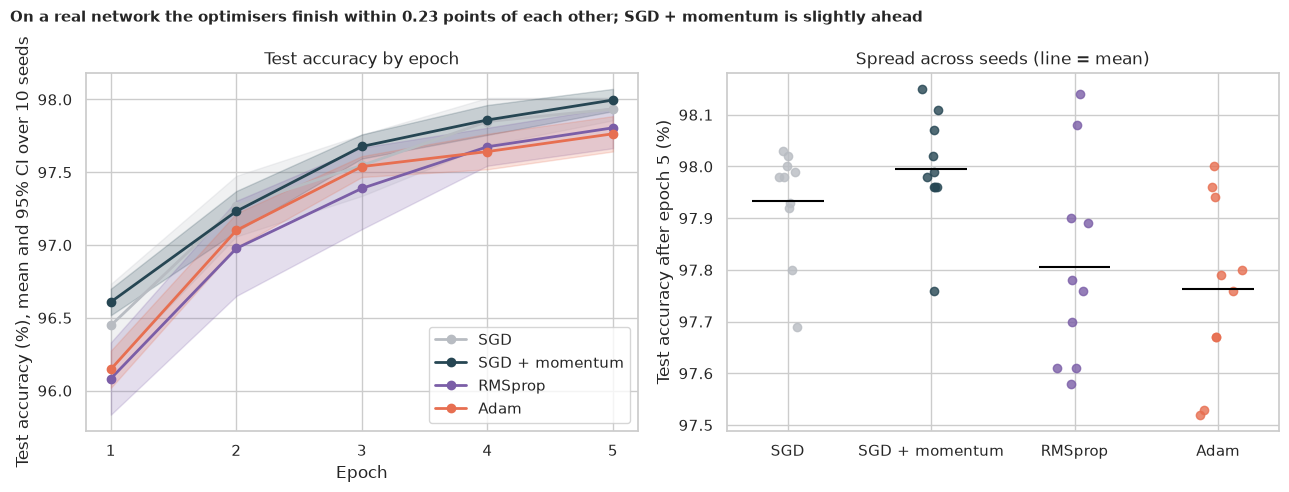

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
epochs = np.arange(1, MNIST_EPOCHS + 1)
for kind in OPTIMIZERS:
    values = accuracy_by_epoch[kind] * 100
    mean = values.mean(axis=0)
    half = stats.t.ppf(0.975, len(values) - 1) * values.std(axis=0, ddof=1) / np.sqrt(len(values))
    axes[0].plot(epochs, mean, marker="o", color=OPT_COLORS[kind], lw=2, label=kind)
    axes[0].fill_between(epochs, mean - half, mean + half, color=OPT_COLORS[kind], alpha=0.2)
axes[0].set_xticks(epochs)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Test accuracy (%), mean and 95% CI over 10 seeds")
axes[0].legend(loc="lower right")
axes[0].set_title("Test accuracy by epoch")

final = {kind: accuracy_by_epoch[kind][:, -1] * 100 for kind in OPTIMIZERS}
for pos, kind in enumerate(OPTIMIZERS):
    axes[1].scatter(
        np.full(N_MNIST_SEEDS, pos) + np.random.default_rng(pos).normal(0, 0.05, 10),
        final[kind],
        color=OPT_COLORS[kind],
        alpha=0.8,
    )
    axes[1].hlines(final[kind].mean(), pos - 0.25, pos + 0.25, color="black")
axes[1].set_xticks(range(len(OPTIMIZERS)), OPTIMIZERS)
axes[1].set_ylabel(f"Test accuracy after epoch {MNIST_EPOCHS} (%)")
axes[1].set_title("Spread across seeds (line = mean)")
spread = max(final[k].mean() for k in OPTIMIZERS) - min(final[k].mean() for k in OPTIMIZERS)
leader = max(OPTIMIZERS, key=lambda k: final[k].mean())
fig.suptitle(
    f"On a real network the optimisers finish within {spread:.2f} points of each other; "
    f"{leader} is slightly ahead",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "04_mnist.png", dpi=150)
plt.show()

**How to read this.** (Test accuracy; higher is better.)

- **The tuned learning rates** came from the validation set: plain SGD **0.3** (note that 1.0 diverged: it scored only 54%, so 0.3 is not at the edge of the grid), SGD + momentum **0.03**, RMSprop **0.001** and Adam **0.001**.
- **After 5 epochs all four optimisers land within about a quarter of a percentage point of each other**: SGD + momentum **98.00%**, SGD **97.93%**, RMSprop **97.80%** and Adam **97.76%**.
- **Adam is *not* the most accurate, and not the fastest, here.** The paired tests (H₄ and H₅) show Adam was **slightly worse** than plain SGD after epoch 1 (−0.30 percentage points, 95% CI −0.55 to −0.03, p ≈ 0.049) and after epoch 5 (−0.17, CI −0.26 to −0.09, p ≈ 0.002), and slightly worse than SGD + momentum at both points (−0.46 and −0.23 points; p ≈ 0.002 and 0.004). Against RMSprop there is no detectable difference (p > 0.69). **So we reject H₀, but in the opposite direction from the textbook story:** on this network, with fair tuning, **a well-tuned classic SGD with momentum finished slightly ahead of Adam.**
- **Why?** MNIST pixels are normalised and every layer's inputs have a similar scale, so this is a *well-conditioned* problem, the opposite of the lopsided regression where Adam shone. When the terrain is already friendly, Adam's clever per-direction shoes have little to fix, and a tuned SGD can edge it out on final accuracy. (Adam is also known to sometimes generalise a touch worse than SGD on image problems; this experiment doesn't test that, but it fits.)
- **The gaps are small** (0.2 to 0.5 percentage points) and each is measured over only 10 seeds, so they are worth knowing about but not worth over-interpreting.

## 10. 🎯 Takeaways

1. **Adam is just momentum plus adaptive step sizes.** Written out, it is a handful of lines, and our version matches `torch.optim.Adam` to 2e-16 over 300 steps.
2. **On a lopsided problem Adam wins clearly, even against tuned rivals.** It needs about 0.08x the steps of plain SGD, 0.32x those of SGD + momentum and 0.57x those of RMSprop (all p < 0.001), and unlike an aggressive RMSprop it settles reliably.
3. **Adam is the most forgiving about its learning rate**: it works across 6 of 13 tested learning rates (a 3-decade window), against 1 for plain SGD and 3 each for momentum and RMSprop.
4. **The advantage is not universal.** On a normalised MNIST network with fairly tuned rates, SGD + momentum ended 0.2 to 0.5 percentage points *more accurate* than Adam. Adam's strength is robustness and speed on awkward terrain, not guaranteed better final accuracy.
5. **Measure convergence honestly.** "First time it touches the line" rewards jumpy optimisers; a sustained-average criterion and tuning among reliable learning rates give a fairer race.

## 11. ⚠️ Limitations and edge cases

- **One toy problem family and one small network.** The lopsided regression and the MNIST MLP are tiny compared with real deep learning, where architecture, normalisation layers and schedules change how optimisers compare.
- **Tuned on small grids.** The learning rates came from 13-point and 4-point grids; a finer search, or tuning momentum and the betas as well, could change the rankings.
- **Censored data.** Runs that never converged are recorded at the 6,000-step budget, which understates the slowest optimisers.
- **Few seeds for the real network.** Ten paired seeds give wide uncertainty on differences of a quarter of a percentage point.
- **Only five optimiser settings.** We used standard defaults for momentum (0.9), RMSprop (0.99) and Adam (0.9, 0.999) and did not test variants such as AdamW, learning-rate schedules or weight decay, which matter a great deal in practice.
- **Accuracy is not the only goal.** Training speed, memory and robustness also matter, and the answer depends on the model and data.

---
*Run `uv run jupyter nbconvert --to html --execute DL/adam-optimizer/adam_optimizer.ipynb --output-dir docs --output dl-adam-optimizer` to rebuild the web version (`docs/dl-adam-optimizer.html`).*